# 04 - Modelado

## Objetivo de este cuaderno

Entrenamos una regresión lineal como línea base para predecir price y medimos su error en euros.

- **Lee:** X_train_esc.csv, X_test_esc.csv, y_train.csv e y_test.csv de data/processed
- **Guarda:** el modelo en models/regresion_lineal.joblib, la figura 11 en outputs/figures y las métricas en outputs/metricas_lineal.csv

### Importar librerías

Cargamos pandas, numpy y matplotlib. Las herramientas de sklearn se importan en la celda donde se usan.

In [96]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Cargar los datos

La regresión lineal usa los datos escalados. y está guardada como una tabla con una columna, price, que contiene el logaritmo del precio; nos quedamos con esa columna.

In [97]:
X_train_esc = pd.read_csv('../data/processed/X_train_esc.csv')
X_test_esc = pd.read_csv('../data/processed/X_test_esc.csv')
y_train = pd.read_csv('../data/processed/y_train.csv')['price']
y_test = pd.read_csv('../data/processed/y_test.csv')['price']
print(X_train_esc.shape, X_test_esc.shape, y_train.shape, y_test.shape)

(32491, 26) (8123, 26) (32491,) (8123,)


# Regresión lineal

### Entrenar el modelo

La regresión lineal busca un peso (coeficiente) para cada variable, de forma que la suma ponderada se parezca lo más posible al logaritmo del precio.

In [98]:
from sklearn.linear_model import LinearRegression
reg = LinearRegression()
reg.fit(X_train_esc, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](26,)","[ 0.2 ,-0.17, 0.25,...,-0.02,-0.01, 0.03]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](26,)","['model','kms','power',...,'make_RENAULT','make_SEAT','make_VOLKSWAGEN']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,9.489
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,26
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(24)


### Predecir

El modelo predice el logaritmo del precio. Para medir el error en euros, deshacemos el logaritmo con np.exp, tanto en las predicciones como en los precios reales.

In [99]:
pred_train_log = reg.predict(X_train_esc)
pred_test_log = reg.predict(X_test_esc)
pred_train = np.exp(pred_train_log)
pred_test = np.exp(pred_test_log)
real_train = np.exp(y_train)
real_test = np.exp(y_test)

# Métricas

- **MAE:** cuántos euros nos equivocamos de media en cada coche.
- **MAPE:** cuánto nos equivocamos de media en porcentaje del precio; un error de 1.000 € pesa más en un coche de 5.000 € que en uno de 50.000 €.
- **RMSE:** como el MAE, pero castiga más los errores grandes.
- **R2:** qué parte de la variación del logaritmo del precio explica el modelo (1 sería perfecto).

Las calculamos en train y en test. Si en train salieran mucho mejor que en test, el modelo estaría memorizando (sobreajuste).

In [100]:
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, r2_score

In [101]:
mae_train = mean_absolute_error(real_train, pred_train)
mape_train = mean_absolute_percentage_error(real_train, pred_train) * 100
rmse_train = np.sqrt(mean_squared_error(real_train, pred_train))
r2_train = r2_score(y_train, pred_train_log)

In [102]:
mae_test = mean_absolute_error(real_test, pred_test)
mape_test = mean_absolute_percentage_error(real_test, pred_test) * 100
rmse_test = np.sqrt(mean_squared_error(real_test, pred_test))
r2_test = r2_score(y_test, pred_test_log)

Juntamos las métricas en una tabla.

In [103]:
metricas = pd.DataFrame({
    'conjunto': ['train', 'test'],
    'MAE (€)': [mae_train, mae_test],
    'MAPE (%)': [mape_train, mape_test],
    'RMSE (€)': [rmse_train, rmse_test],
    'R2 (log)': [r2_train, r2_test]
})
metricas.round(3)

,conjunto,MAE (€),MAPE (%),RMSE (€),R2 (log)
0,train,2619.699,16.791,5110.706,0.906
1,test,2664.474,16.803,5301.915,0.907


### Coches con un error menor del 15 %

El margen de la empresa ronda el 15 %. Miramos en qué porcentaje de coches de test el error de la tasación queda por debajo de ese margen.

In [104]:
error_relativo = np.abs(pred_test - real_test) / real_test
dentro_margen = (error_relativo < 0.15).mean() * 100
print(round(dentro_margen, 1))

58.7


### Coeficientes

En 03_preprocesado dejamos todas las categorías de combustible y de marca. Esas columnas son redundantes entre sí (en cada grupo siempre suman 1), así que miramos si algún coeficiente sale desproporcionado.

In [105]:
coef = pd.Series(reg.coef_, index=X_train_esc.columns)
coef.sort_values()

age                       -0.327527
kms                       -0.170274
fuel_Gasolina             -0.027468
make_OPEL                 -0.026786
doors                     -0.020673
isla                      -0.019747
make_CITROEN              -0.019629
make_FORD                 -0.016883
make_RENAULT              -0.016096
make_PEUGEOT              -0.015595
fuel_Híbrido enchufable   -0.012004
make_Other                -0.011196
make_SEAT                 -0.010783
fuel_Gas licuado (GLP)    -0.010108
fuel_Eléctrico            -0.008856
fuel_Híbrido              -0.004870
fuel_Gas natural (CNG)    -0.001946
make_BMW                   0.022295
make_MERCEDES-BENZ         0.027097
make_VOLKSWAGEN            0.028493
make_AUDI                  0.030696
is_professional            0.032000
fuel_Diésel                0.034191
shift                      0.049988
model                      0.196402
power                      0.248729
dtype: float64

In [106]:
reg.intercept_

np.float64(9.48869086576277)

### Real frente a predicho

Cada punto es un coche de test. Si la predicción fuera perfecta, todos los puntos estarían sobre la línea roja.

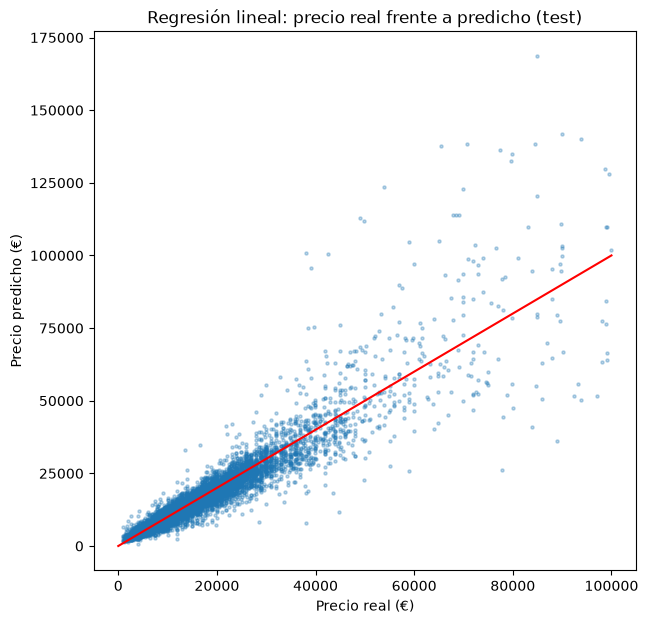

In [107]:
plt.figure(figsize=(7, 7))
plt.scatter(real_test, pred_test, s=5, alpha=0.3)
plt.plot([0, 100000], [0, 100000], color='red')
plt.xlabel('Precio real (€)')
plt.ylabel('Precio predicho (€)')
plt.title('Regresión lineal: precio real frente a predicho (test)')
plt.savefig('../outputs/figures/11_real_vs_predicho_lineal.png', bbox_inches='tight')
plt.show()

# Guardar el modelo y las métricas

Guardamos el modelo entrenado con joblib, que guarda el objeto de Python en un archivo para cargarlo después sin volver a entrenar.

In [108]:
import joblib
joblib.dump(reg, '../models/regresion_lineal.joblib')

['../models/regresion_lineal.joblib']

In [109]:
metricas.to_csv('../outputs/metricas_lineal.csv', index=False)

## Observaciones

- En test, la regresión lineal se equivoca de media 2.664 € por coche (MAE) y un 16,8 % del precio (MAPE). El RMSE es 5.302 €, bastante mayor que el MAE: hay algunos coches con errores grandes.
- El R2 en el logaritmo del precio es 0,907: el modelo explica la mayor parte de la variación.
- Train y test dan casi lo mismo (MAE 2.620 € frente a 2.664 €, R2 0,906 frente a 0,907), así que no hay sobreajuste.
- Solo el 58,7 % de los coches de test tiene un error menor del 15 %, que es el margen de la empresa, por lo que lo mejor es evaluar otros modelos.
- Los coeficientes no salen desproporcionados a pesar de las columnas redundantes: todos están entre -0,33 y 0,25. Las variables con más peso son age y kms (bajan el precio) y power y model (lo suben).
- Por esa redundancia, los coeficientes de combustible y de marca no se pueden leer uno a uno: solo tiene sentido compararlos entre sí dentro de cada grupo.

## Random Forest

Un Random Forest entrena muchos árboles de decisión, cada uno con una muestra al azar de los coches y de las variables, y su predicción es la media de todos los árboles. Los árboles no necesitan que las variables estén en la misma escala, así que usamos X_train y X_test sin escalar.

### Cargar los datos sin escalar

y_train e y_test son los mismos que en la regresión lineal.

In [110]:
X_train = pd.read_csv('../data/processed/X_train.csv')
X_test = pd.read_csv('../data/processed/X_test.csv')
print(X_train.shape, X_test.shape)

(32491, 26) (8123, 26)


### Modelo base

Primero entrenamos el Random Forest con los parámetros por defecto. n_jobs=-1 usa todos los núcleos del ordenador para entrenar más rápido.

In [111]:
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

Predecimos en train y en test y deshacemos el logaritmo con np.exp para tener euros.

In [112]:
rf_pred_train = np.exp(rf.predict(X_train))
rf_pred_test = np.exp(rf.predict(X_test))

Calculamos las mismas métricas que en la regresión lineal.

In [113]:
rf_mae_train = mean_absolute_error(real_train, rf_pred_train)
rf_mape_train = mean_absolute_percentage_error(real_train, rf_pred_train) * 100
rf_rmse_train = np.sqrt(mean_squared_error(real_train, rf_pred_train))
rf_r2_train = r2_score(y_train, np.log(rf_pred_train))

In [114]:
rf_mae_test = mean_absolute_error(real_test, rf_pred_test)
rf_mape_test = mean_absolute_percentage_error(real_test, rf_pred_test) * 100
rf_rmse_test = np.sqrt(mean_squared_error(real_test, rf_pred_test))
rf_r2_test = r2_score(y_test, np.log(rf_pred_test))

In [115]:
metricas_rf = pd.DataFrame({
    'conjunto': ['train', 'test'],
    'MAE (€)': [rf_mae_train, rf_mae_test],
    'MAPE (%)': [rf_mape_train, rf_mape_test],
    'RMSE (€)': [rf_rmse_train, rf_rmse_test],
    'R2 (log)': [rf_r2_train, rf_r2_test]
})
metricas_rf.round(3)

,conjunto,MAE (€),MAPE (%),RMSE (€),R2 (log)
0,train,679.232,4.684,1216.504,0.991
1,test,1848.674,12.875,3442.529,0.938


Porcentaje de coches de test con un error menor del 15 %.

In [116]:
rf_error_relativo = np.abs(rf_pred_test - real_test) / real_test
rf_dentro_margen = (rf_error_relativo < 0.15).mean() * 100
print(round(rf_dentro_margen, 1))

71.3


### Ajuste de hiperparámetros

Los hiperparámetros son opciones del modelo que no se aprenden de los datos: hay que elegirlas. Probamos varias combinaciones con RandomizedSearchCV:

- **n_estimators:** número de árboles.
- **max_depth:** profundidad máxima de cada árbol (None es sin límite).
- **min_samples_leaf:** número mínimo de coches en cada hoja; si es mayor, el árbol memoriza menos.
- **max_features:** parte de las variables que mira cada árbol en cada división.

RandomizedSearchCV no prueba todas las combinaciones, sino n_iter=10 elegidas al azar. Cada una se evalúa con validación cruzada (cv=3): train se divide en 3 partes, se entrena con 2 y se mide con la tercera, tres veces. Usamos solo train, así que test sigue sin usarse. Como medida usamos el MAE; sklearn siempre busca el valor más alto, por eso se escribe neg_mean_absolute_error (el MAE en negativo). Aquí el MAE está en la escala del logaritmo, no en euros.

In [117]:
from sklearn.model_selection import RandomizedSearchCV
params = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_leaf': [1, 2, 5, 10],
    'max_features': [1.0, 0.5, 'sqrt']
}
busqueda = RandomizedSearchCV(RandomForestRegressor(random_state=42), params, n_iter=10, cv=3,
                              scoring='neg_mean_absolute_error', random_state=42, n_jobs=-1)
busqueda.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [None, 10, ...], 'max_features': [1.0, 0.5, ...], 'min_samples_leaf': [1, 2, ...], 'n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` in

Mejor combinación encontrada.

In [118]:
busqueda.best_params_

{'n_estimators': 100,
 'min_samples_leaf': 1,
 'max_features': 0.5,
 'max_depth': None}

Nos quedamos con el mejor modelo, que RandomizedSearchCV ya ha vuelto a entrenar con todo train.

In [119]:
rf_mejor = busqueda.best_estimator_
rfm_pred_train = np.exp(rf_mejor.predict(X_train))
rfm_pred_test = np.exp(rf_mejor.predict(X_test))

Métricas del modelo ajustado.

In [120]:
rfm_mae_train = mean_absolute_error(real_train, rfm_pred_train)
rfm_mape_train = mean_absolute_percentage_error(real_train, rfm_pred_train) * 100
rfm_rmse_train = np.sqrt(mean_squared_error(real_train, rfm_pred_train))
rfm_r2_train = r2_score(y_train, np.log(rfm_pred_train))

In [121]:
rfm_mae_test = mean_absolute_error(real_test, rfm_pred_test)
rfm_mape_test = mean_absolute_percentage_error(real_test, rfm_pred_test) * 100
rfm_rmse_test = np.sqrt(mean_squared_error(real_test, rfm_pred_test))
rfm_r2_test = r2_score(y_test, np.log(rfm_pred_test))

In [122]:
metricas_rfm = pd.DataFrame({
    'conjunto': ['train', 'test'],
    'MAE (€)': [rfm_mae_train, rfm_mae_test],
    'MAPE (%)': [rfm_mape_train, rfm_mape_test],
    'RMSE (€)': [rfm_rmse_train, rfm_rmse_test],
    'R2 (log)': [rfm_r2_train, rfm_r2_test]
})
metricas_rfm.round(3)

,conjunto,MAE (€),MAPE (%),RMSE (€),R2 (log)
0,train,669.900,4.569,1229.111,0.992
1,test,1816.342,12.595,3372.336,0.940


Porcentaje de coches de test con un error menor del 15 %.

In [123]:
rfm_error_relativo = np.abs(rfm_pred_test - real_test) / real_test
rfm_dentro_margen = (rfm_error_relativo < 0.15).mean() * 100
print(round(rfm_dentro_margen, 1))

72.7


### Comparación en test

Juntamos las métricas de test de la regresión lineal, el Random Forest base y el ajustado.

In [124]:
comparacion = pd.DataFrame({
    'modelo': ['Regresión lineal', 'Random Forest base', 'Random Forest ajustado'],
    'MAE (€)': [mae_test, rf_mae_test, rfm_mae_test],
    'MAPE (%)': [mape_test, rf_mape_test, rfm_mape_test],
    'RMSE (€)': [rmse_test, rf_rmse_test, rfm_rmse_test],
    'R2 (log)': [r2_test, rf_r2_test, rfm_r2_test],
    'Error < 15 % (%)': [dentro_margen, rf_dentro_margen, rfm_dentro_margen]
})
comparacion.round(3)

,modelo,MAE (€),MAPE (%),RMSE (€),R2 (log),Error < 15 % (%)
0,Regresión lineal,2664.474,16.803,5301.915,0.907,58.722
1,Random Forest base,1848.674,12.875,3442.529,0.938,71.267
2,Random Forest ajustado,1816.342,12.595,3372.336,0.940,72.732


### Importancia de las variables

El Random Forest indica cuánto ha usado cada variable para reducir el error en sus divisiones. Cuanto mayor, más importante.

In [125]:
importancias = pd.Series(rf_mejor.feature_importances_, index=X_train.columns).sort_values()
importancias

fuel_Gas natural (CNG)     0.000045
fuel_Híbrido enchufable    0.000276
fuel_Gas licuado (GLP)     0.000297
fuel_Híbrido               0.000422
fuel_Eléctrico             0.000608
make_SEAT                  0.000825
make_CITROEN               0.000939
make_BMW                   0.001058
make_FORD                  0.001123
make_AUDI                  0.001173
make_RENAULT               0.001222
make_OPEL                  0.001302
make_PEUGEOT               0.001771
isla                       0.001972
make_VOLKSWAGEN            0.002219
fuel_Diésel                0.002787
make_MERCEDES-BENZ         0.002807
fuel_Gasolina              0.002833
make_Other                 0.003240
doors                      0.006009
is_professional            0.010417
shift                      0.051636
kms                        0.132129
power                      0.158450
model                      0.270850
age                        0.343590
dtype: float64

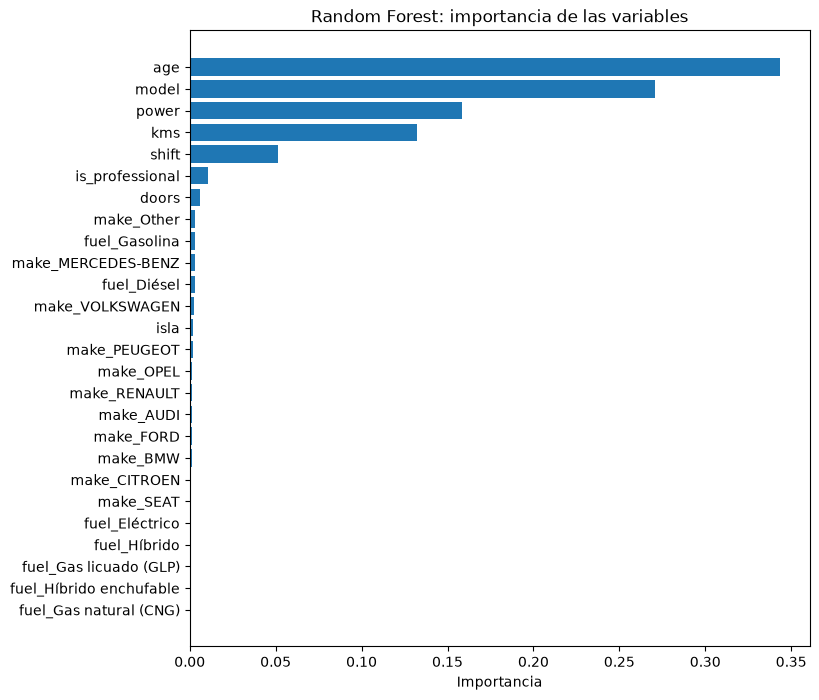

In [126]:
plt.figure(figsize=(8, 8))
plt.barh(importancias.index, importancias.values)
plt.xlabel('Importancia')
plt.title('Random Forest: importancia de las variables')
plt.savefig('../outputs/figures/12_importancia_random_forest.png', bbox_inches='tight')
plt.show()

### Real frente a predicho

Cada punto es un coche de test. Si la predicción fuera perfecta, todos los puntos estarían sobre la línea roja.

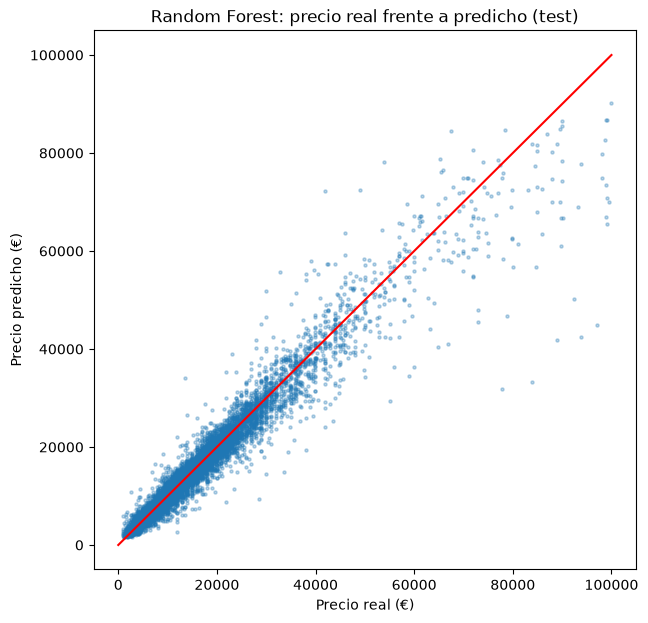

In [127]:
plt.figure(figsize=(7, 7))
plt.scatter(real_test, rfm_pred_test, s=5, alpha=0.3)
plt.plot([0, 100000], [0, 100000], color='red')
plt.xlabel('Precio real (€)')
plt.ylabel('Precio predicho (€)')
plt.title('Random Forest: precio real frente a predicho (test)')
plt.savefig('../outputs/figures/13_real_vs_predicho_random_forest.png', bbox_inches='tight')
plt.show()

### Guardar el modelo y las métricas

Guardamos el Random Forest ajustado y sus métricas de train y test.

In [128]:
joblib.dump(rf_mejor, '../models/random_forest.joblib')

['../models/random_forest.joblib']

In [129]:
metricas_rfm.to_csv('../outputs/metricas_random_forest.csv', index=False)

## Observaciones del Random Forest

- El Random Forest base ya mejora mucho a la regresión lineal en test: MAE de 1.849 € frente a 2.664 € y MAPE del 12,9 % frente al 16,8 %.
- El ajuste de hiperparámetros mejora poco: la mejor combinación (100 árboles, sin límite de profundidad, min_samples_leaf 1 y max_features 0,5) deja el MAE de test en 1.816 €, el MAPE en 12,6 % y el RMSE en 3.372 €. El R2 en el logaritmo pasa de 0,938 a 0,940.
- Con el modelo ajustado, el 72,7 % de los coches de test tiene un error menor del 15 %, frente al 58,7 % de la regresión lineal.
- Hay sobreajuste: en train el MAE es 670 € y el MAPE 4,6 %, casi tres veces mejor que en test (1.816 € y 12,6 %). El modelo memoriza parte de train, aunque en test sigue siendo el mejor de los tres.
- Las variables más importantes son age (0,34), model (0,27), power (0,16) y kms (0,13); después viene shift (0,05). Combustible, marca, isla, doors e is_professional pesan muy poco por separado.

## XGBoost

XGBoost también usa muchos árboles, pero los construye uno detrás de otro: cada árbol nuevo intenta corregir los errores que dejan los anteriores, y la predicción es la suma de todos. Como el Random Forest, no necesita escalado, así que usamos X_train y X_test sin escalar, que ya están cargados.

### Modelo base

Primero entrenamos XGBoost con los parámetros por defecto.

In [130]:
from xgboost import XGBRegressor
xgb = XGBRegressor(random_state=42, n_jobs=-1)
xgb.fit(X_train, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


Predecimos en train y en test y deshacemos el logaritmo con np.exp para tener euros.

In [131]:
xgb_pred_train = np.exp(xgb.predict(X_train))
xgb_pred_test = np.exp(xgb.predict(X_test))

Calculamos las mismas métricas que en los modelos anteriores.

In [132]:
xgb_mae_train = mean_absolute_error(real_train, xgb_pred_train)
xgb_mape_train = mean_absolute_percentage_error(real_train, xgb_pred_train) * 100
xgb_rmse_train = np.sqrt(mean_squared_error(real_train, xgb_pred_train))
xgb_r2_train = r2_score(y_train, np.log(xgb_pred_train))

In [133]:
xgb_mae_test = mean_absolute_error(real_test, xgb_pred_test)
xgb_mape_test = mean_absolute_percentage_error(real_test, xgb_pred_test) * 100
xgb_rmse_test = np.sqrt(mean_squared_error(real_test, xgb_pred_test))
xgb_r2_test = r2_score(y_test, np.log(xgb_pred_test))

In [134]:
metricas_xgb = pd.DataFrame({
    'conjunto': ['train', 'test'],
    'MAE (€)': [xgb_mae_train, xgb_mae_test],
    'MAPE (%)': [xgb_mape_train, xgb_mape_test],
    'RMSE (€)': [xgb_rmse_train, xgb_rmse_test],
    'R2 (log)': [xgb_r2_train, xgb_r2_test]
})
metricas_xgb.round(3)

,conjunto,MAE (€),MAPE (%),RMSE (€),R2 (log)
0,train,1572.917,10.687,2463.009,0.961
1,test,1917.799,13.073,3333.062,0.940


Porcentaje de coches de test con un error menor del 15 %.

In [135]:
xgb_error_relativo = np.abs(xgb_pred_test - real_test) / real_test
xgb_dentro_margen = (xgb_error_relativo < 0.15).mean() * 100
print(round(xgb_dentro_margen, 1))

69.9


### Ajuste de hiperparámetros

Usamos RandomizedSearchCV igual que con el Random Forest (10 combinaciones al azar, validación cruzada con cv=3 sobre train y MAE como medida). Los hiperparámetros que probamos son:

- **n_estimators:** número de árboles.
- **max_depth:** profundidad máxima de cada árbol.
- **learning_rate:** cuánto corrige cada árbol nuevo; un valor pequeño corrige poco a poco y necesita más árboles.
- **subsample:** parte de los coches que usa cada árbol (1.0 son todos).
- **colsample_bytree:** parte de las variables que usa cada árbol (1.0 son todas).

Cada modelo de la búsqueda usa un solo núcleo (n_jobs=1) y es la búsqueda la que reparte las combinaciones entre los núcleos, para no repartir dos veces el mismo trabajo.

In [136]:
params_xgb = {
    'n_estimators': [200, 400, 600],
    'max_depth': [4, 6, 8],
    'learning_rate': [0.03, 0.05, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.7, 1.0]
}
busqueda_xgb = RandomizedSearchCV(XGBRegressor(random_state=42, n_jobs=1), params_xgb, n_iter=10, cv=3,
                                  scoring='neg_mean_absolute_error', random_state=42, n_jobs=-1)
busqueda_xgb.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.7, 1.0], 'learning_rate': [0.03, 0.05, ...], 'max_depth': [4, 6, ...], 'n_estimators': [200, 400, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV

Mejor combinación encontrada.

In [137]:
busqueda_xgb.best_params_

{'subsample': 1.0,
 'n_estimators': 400,
 'max_depth': 6,
 'learning_rate': 0.1,
 'colsample_bytree': 0.7}

Nos quedamos con el mejor modelo, que RandomizedSearchCV ya ha vuelto a entrenar con todo train.

In [138]:
xgb_mejor = busqueda_xgb.best_estimator_
xgbm_pred_train = np.exp(xgb_mejor.predict(X_train))
xgbm_pred_test = np.exp(xgb_mejor.predict(X_test))

Métricas del modelo ajustado.

In [139]:
xgbm_mae_train = mean_absolute_error(real_train, xgbm_pred_train)
xgbm_mape_train = mean_absolute_percentage_error(real_train, xgbm_pred_train) * 100
xgbm_rmse_train = np.sqrt(mean_squared_error(real_train, xgbm_pred_train))
xgbm_r2_train = r2_score(y_train, np.log(xgbm_pred_train))

In [140]:
xgbm_mae_test = mean_absolute_error(real_test, xgbm_pred_test)
xgbm_mape_test = mean_absolute_percentage_error(real_test, xgbm_pred_test) * 100
xgbm_rmse_test = np.sqrt(mean_squared_error(real_test, xgbm_pred_test))
xgbm_r2_test = r2_score(y_test, np.log(xgbm_pred_test))

In [141]:
metricas_xgbm = pd.DataFrame({
    'conjunto': ['train', 'test'],
    'MAE (€)': [xgbm_mae_train, xgbm_mae_test],
    'MAPE (%)': [xgbm_mape_train, xgbm_mape_test],
    'RMSE (€)': [xgbm_rmse_train, xgbm_rmse_test],
    'R2 (log)': [xgbm_r2_train, xgbm_r2_test]
})
metricas_xgbm.round(3)

,conjunto,MAE (€),MAPE (%),RMSE (€),R2 (log)
0,train,1498.705,10.151,2380.222,0.965
1,test,1853.692,12.718,3248.200,0.942


Porcentaje de coches de test con un error menor del 15 %.

In [142]:
xgbm_error_relativo = np.abs(xgbm_pred_test - real_test) / real_test
xgbm_dentro_margen = (xgbm_error_relativo < 0.15).mean() * 100
print(round(xgbm_dentro_margen, 1))

71.5


### Comparación en test

Juntamos las métricas de test de todos los modelos entrenados en este cuaderno.

In [143]:
comparacion_final = pd.DataFrame({
    'modelo': ['Regresión lineal', 'Random Forest base', 'Random Forest ajustado', 'XGBoost base', 'XGBoost ajustado'],
    'MAE (€)': [mae_test, rf_mae_test, rfm_mae_test, xgb_mae_test, xgbm_mae_test],
    'MAPE (%)': [mape_test, rf_mape_test, rfm_mape_test, xgb_mape_test, xgbm_mape_test],
    'RMSE (€)': [rmse_test, rf_rmse_test, rfm_rmse_test, xgb_rmse_test, xgbm_rmse_test],
    'R2 (log)': [r2_test, rf_r2_test, rfm_r2_test, xgb_r2_test, xgbm_r2_test],
    'Error < 15 % (%)': [dentro_margen, rf_dentro_margen, rfm_dentro_margen, xgb_dentro_margen, xgbm_dentro_margen]
})
comparacion_final.round(3)

,modelo,MAE (€),MAPE (%),RMSE (€),R2 (log),Error < 15 % (%)
0,Regresión lineal,2664.474,16.803,5301.915,0.907,58.722
1,Random Forest base,1848.674,12.875,3442.529,0.938,71.267
2,Random Forest ajustado,1816.342,12.595,3372.336,0.940,72.732
3,XGBoost base,1917.799,13.073,3333.062,0.940,69.913
4,XGBoost ajustado,1853.692,12.718,3248.200,0.942,71.488


### Importancia de las variables

XGBoost también indica cuánto ha aportado cada variable a reducir el error. Cuanto mayor, más importante.

In [144]:
importancias_xgb = pd.Series(xgb_mejor.feature_importances_, index=X_train.columns).sort_values()
importancias_xgb

fuel_Gas natural (CNG)     0.002516
fuel_Híbrido enchufable    0.003035
fuel_Híbrido               0.004574
make_CITROEN               0.005207
make_FORD                  0.005639
make_RENAULT               0.006715
make_SEAT                  0.007089
make_Other                 0.007414
isla                       0.008023
doors                      0.009279
fuel_Eléctrico             0.010419
make_BMW                   0.010683
fuel_Diésel                0.014191
make_PEUGEOT               0.014471
make_OPEL                  0.014621
make_AUDI                  0.016400
fuel_Gasolina              0.017755
is_professional            0.018675
fuel_Gas licuado (GLP)     0.020319
make_VOLKSWAGEN            0.023000
make_MERCEDES-BENZ         0.030503
kms                        0.043166
shift                      0.067211
power                      0.126132
model                      0.127226
age                        0.385735
dtype: float32

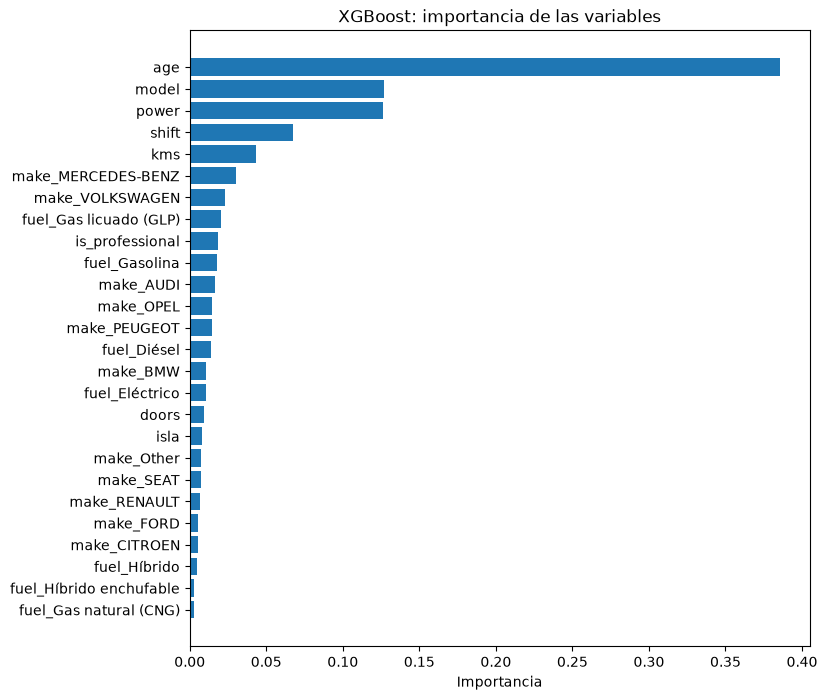

In [145]:
plt.figure(figsize=(8, 8))
plt.barh(importancias_xgb.index, importancias_xgb.values)
plt.xlabel('Importancia')
plt.title('XGBoost: importancia de las variables')
plt.savefig('../outputs/figures/14_importancia_xgboost.png', bbox_inches='tight')
plt.show()

### Real frente a predicho

Cada punto es un coche de test. Si la predicción fuera perfecta, todos los puntos estarían sobre la línea roja.

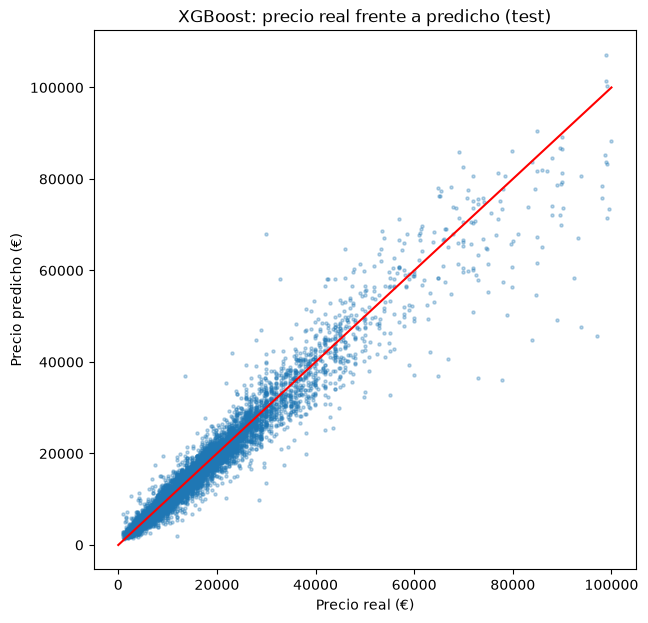

In [146]:
plt.figure(figsize=(7, 7))
plt.scatter(real_test, xgbm_pred_test, s=5, alpha=0.3)
plt.plot([0, 100000], [0, 100000], color='red')
plt.xlabel('Precio real (€)')
plt.ylabel('Precio predicho (€)')
plt.title('XGBoost: precio real frente a predicho (test)')
plt.savefig('../outputs/figures/15_real_vs_predicho_xgboost.png', bbox_inches='tight')
plt.show()

### Guardar el modelo y las métricas

Guardamos el XGBoost ajustado y sus métricas de train y test.

In [147]:
joblib.dump(xgb_mejor, '../models/xgboost.joblib')

['../models/xgboost.joblib']

In [148]:
metricas_xgbm.to_csv('../outputs/metricas_xgboost.csv', index=False)

## Observaciones del XGBoost

- El XGBoost base se equivoca en test 1.918 € de media (MAE), un 13,1 % del precio (MAPE), con un RMSE de 3.333 €. El 69,9 % de los coches de test tiene un error menor del 15 %.
- La mejor combinación de la búsqueda es 400 árboles, max_depth 6, learning_rate 0,1, subsample 1,0 y colsample_bytree 0,7. Con ella el MAE de test baja a 1.854 €, el MAPE a 12,7 % y el RMSE a 3.248 €; el R2 en el logaritmo es 0,942 y el 71,5 % de los coches queda por debajo del 15 % de error.
- La diferencia entre train y test es menor que en el Random Forest: el XGBoost ajustado tiene un MAE de 1.499 € en train y 1.854 € en test, mientras que el Random Forest ajustado tiene 682 € en train y 1.835 € en test.
- En test, el Random Forest ajustado tiene el MAE más bajo (1.835 €), el MAPE más bajo (12,7 %) y el mayor porcentaje de coches con error menor del 15 % (72,8 %). El XGBoost ajustado tiene el RMSE más bajo (3.248 €) y el R2 más alto (0,942), es decir, comete menos errores muy grandes. Las diferencias entre los dos son pequeñas, y los dos mejoran mucho a la regresión lineal.
- La variable más importante para el XGBoost es age (0,39), seguida de model (0,13), power (0,13), shift (0,07) y kms (0,04).